# 04 - Error analysis of the final LightGBM model

Analysis of the final config's forecast on the scored validation window (2016-03-28 -> 2016-04-24).
The config was chosen on the inner window (2016-02-29 -> 2016-03-27) only; nothing here feeds back into model selection.
Logic lives in `src/analysis.py`; this notebook only calls it.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd
import shap

from src import analysis

FINAL = "final"  # experiment name in artifacts/experiments.jsonl
pd.set_option("display.float_format", "{:.4f}".format)

ctx = analysis.load_context(FINAL)
table = analysis.series_table(ctx)
scores = pd.DataFrame({
    "Seasonal Naive": ctx["evaluator"].level_scores(ctx["actual"], ctx["snaive"]),
    "LightGBM": ctx["evaluator"].level_scores(ctx["actual"], ctx["pred"]),
})
print(scores.mean().round(4).to_string())
ctx["events"]

Seasonal Naive   0.9228
LightGBM         0.5599


,date,event_name_1,event_type_1


## 1. Where the error comes from: category, department, store

Contribution of each item-store series = dollar weight x RMSSE (level 12). `error_share` is the share of the
level-12 WRMSSE, `weight_share` its share of dollar sales; `over_index` > 1 means the group is harder than its weight.

In [2]:
analysis.error_share(table, "cat_id")

,series,weight_share,error_share,wrmsse,wrmsse_snaive,over_index
cat_id,,,,,,
FOODS,14370,0.5697,0.5791,0.8601,1.1373,1.0165
HOUSEHOLD,10470,0.3016,0.3004,0.8427,1.1184,0.9960
HOBBIES,5650,0.1287,0.1205,0.7923,1.0927,0.9363


In [3]:
analysis.error_share(table, "dept_id")

,series,weight_share,error_share,wrmsse,wrmsse_snaive,over_index
dept_id,,,,,,
FOODS_3,8230,0.3472,0.3469,0.8453,1.0816,0.9990
HOUSEHOLD_1,5320,0.2292,0.2327,0.8589,1.1227,1.0151
FOODS_2,3980,0.1557,0.1656,0.8998,1.2175,1.0635
HOBBIES_1,4160,0.1228,0.1152,0.7938,1.0913,0.9381
HOUSEHOLD_2,5150,0.0724,0.0678,0.7917,1.1047,0.9357
FOODS_1,2160,0.0668,0.0666,0.8443,1.2402,0.9978
HOBBIES_2,1490,0.0059,0.0053,0.7605,1.1228,0.8989


In [4]:
analysis.error_share(table, "store_id")

,series,weight_share,error_share,wrmsse,wrmsse_snaive,over_index
store_id,,,,,,
CA_3,3049,0.1580,0.1587,0.8502,1.0946,1.0048
WI_2,3049,0.1170,0.1354,0.9791,1.2931,1.1572
CA_2,3049,0.1023,0.1065,0.8806,1.1779,1.0408
CA_1,3049,0.1091,0.1038,0.8049,1.0715,0.9513
TX_3,3049,0.0989,0.0980,0.8378,1.1196,0.9902
TX_2,3049,0.1013,0.0906,0.7573,1.0458,0.8951
WI_3,3049,0.0839,0.0843,0.8501,1.0977,1.0047
WI_1,3049,0.0860,0.0842,0.8286,1.1355,0.9793
TX_1,3049,0.0792,0.0760,0.8119,1.0798,0.9595


## 2. Top 20 series by weighted error

In [5]:
top = analysis.top_series(table, ctx, n=20)
print(f"Top 20 series = {top['share'].sum():.1%} of level-12 error, {top['weight'].sum():.1%} of weight")
print(f"All series: median zero share {table['zero_share'].median():.2f}, "
      f"median mean sales {table['mean_sales'].median():.2f}, "
      f"share with a price change in val weeks {(table['price_changes_val'] > 0).mean():.1%}")
top

Top 20 series = 4.2% of level-12 error, 2.7% of weight
All series: median zero share 0.64, median mean sales 0.57, share with a price change in val weeks 2.5%


,dept_id,store_id,share,weight,rmsse,rmsse_snaive,actual_28d,pred_28d,bias,mean_sales,zero_share,price_changes_val,event_day_sq_err_share
id,,,,,,,,,,,,,
FOODS_1_096_WI_2_validation,FOODS_1,WI_2,0.0047,0.0032,1.2215,1.3048,1518.0000,1392.0660,-0.0830,41.7918,0.0356,0,0.0000
HOBBIES_1_354_TX_3_validation,HOBBIES_1,TX_3,0.0037,0.0040,0.7717,1.2747,578.0000,627.1295,0.0850,23.1205,0.0219,0,0.0000
HOBBIES_1_158_TX_3_validation,HOBBIES_1,TX_3,0.0028,0.0034,0.7044,1.1397,594.0000,557.3303,-0.0617,18.9753,0.0110,0,0.0000
FOODS_3_382_CA_3_validation,FOODS_3,CA_3,0.0025,0.0005,4.5808,1.4491,17.0000,467.6772,26.5104,3.6658,0.3973,0,0.0000
HOUSEHOLD_1_106_CA_3_validation,HOUSEHOLD_1,CA_3,0.0025,0.0012,1.7169,2.0776,394.0000,351.5119,-0.1078,9.8000,0.0630,0,0.0000
HOUSEHOLD_1_328_CA_3_validation,HOUSEHOLD_1,CA_3,0.0023,0.0008,2.3194,2.2860,479.0000,349.6611,-0.2700,7.3616,0.0877,0,0.0000
FOODS_3_511_CA_1_validation,FOODS_3,CA_1,0.0020,0.0013,1.2278,1.1547,600.0000,450.8990,-0.2485,11.5151,0.4630,0,0.0000
FOODS_3_587_TX_3_validation,FOODS_3,TX_3,0.0019,0.0008,2.0422,1.3509,569.0000,1125.3951,0.9778,31.8986,0.0027,0,0.0000
FOODS_1_096_WI_3_validation,FOODS_1,WI_3,0.0019,0.0011,1.4320,2.2884,676.0000,543.0186,-0.1967,11.0795,0.4164,0,0.0000


The top series are **not** the intermittent ones: most are dense, mid-to-high-volume items. None had a price
change in the val weeks, and the val window contains no calendar events (Easter is 03-27, Pesach End 04-30), so
`event_day_sq_err_share` is 0 everywhere. What they have in common is a **level change the features cannot explain**,
of two kinds (plots below; shading = the last 28 train days, invisible to the forecast because every sales feature
is lagged >= 28 days):

- Spike or drop inside the blind spot -> over-forecast: FOODS_3_382_CA_3 sold ~50-60/day from 03-05 to 03-19 and then
  went back to ~3/day; the lagged rolling means still contain the spike in val. FOODS_3_587_TX_3 dropped late in train
  and the model kept forecasting the old level.
- Jumps that start inside the val window -> under-forecast: FOODS_2_013_WI_2 and HOUSEHOLD_1_535_CA_3 surge during val
  with no price change or event (likely promotions/displays not in the data). 13 of the top 20 are under-forecast.

Top 20: 7 over-forecast, 13 under-forecast; median zero share 0.08, median mean sales 11.3
Total 28-day bias over all series: -2.4%


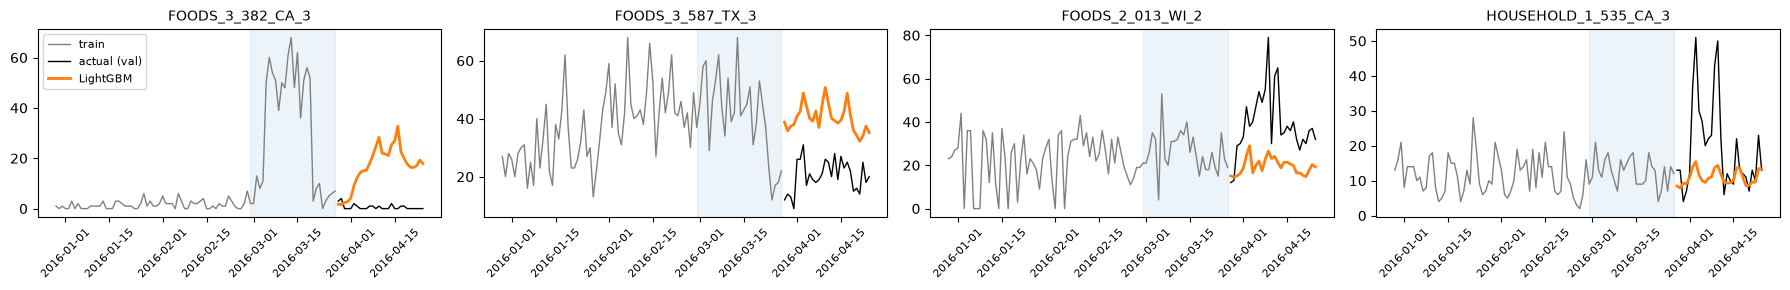

In [6]:
print(f"Top 20: {(top['bias'] > 0).sum()} over-forecast, {(top['bias'] < 0).sum()} under-forecast; "
      f"median zero share {top['zero_share'].median():.2f}, median mean sales {top['mean_sales'].median():.1f}")
print(f"Total 28-day bias over all series: {table['pred_28d'].sum() / table['actual_28d'].sum() - 1:+.1%}")
analysis.plot_series(ctx, ["FOODS_3_382_CA_3_validation", "FOODS_3_587_TX_3_validation",
                           "FOODS_2_013_WI_2_validation", "HOUSEHOLD_1_535_CA_3_validation"], ax_size=(4.5, 3));

## 3. Error by forecast day and day of week

Weighted mean absolute scaled error per day (`*_abs`) and signed scaled error (`*_bias`, > 0 = over-forecast).

,date,dow,event,lgbm_abs,lgbm_bias,snaive_abs,snaive_bias
h,,,,,,,
1,2016-03-28,Mon,False,0.0034,-0.0034,0.2231,0.2231
2,2016-03-29,Tue,False,0.0398,0.0398,0.2737,0.2737
3,2016-03-30,Wed,False,0.3173,0.3173,0.4105,0.4105
4,2016-03-31,Thu,False,0.0415,0.0415,0.1147,-0.1147
5,2016-04-01,Fri,False,0.4243,-0.4243,0.0127,0.0127
6,2016-04-02,Sat,False,0.1700,-0.1700,0.2014,0.2014
7,2016-04-03,Sun,False,0.4003,-0.4003,1.7024,-1.7024
8,2016-04-04,Mon,False,0.1326,-0.1326,0.5172,-0.5172
9,2016-04-05,Tue,False,0.0133,-0.0133,0.7117,-0.7117


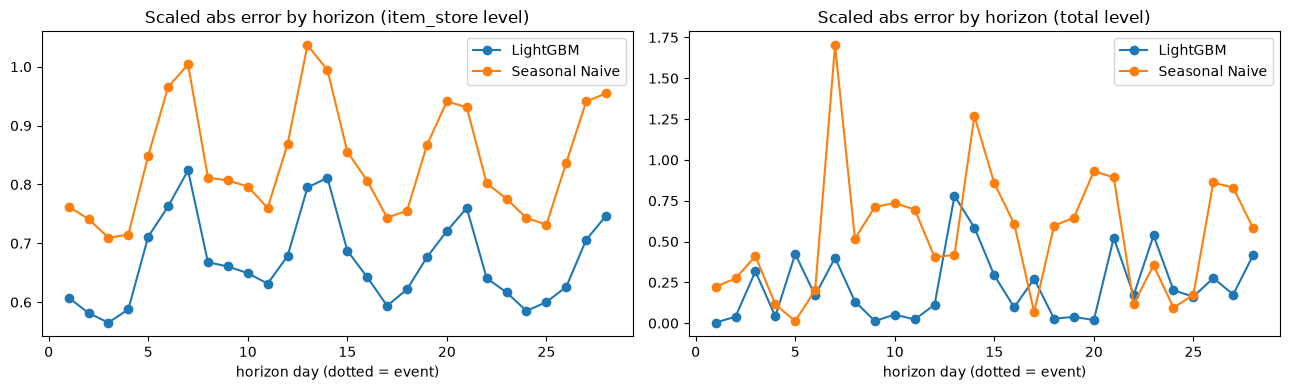

In [7]:
hz = analysis.error_by_horizon(ctx, "item_store")
hz_total = analysis.error_by_horizon(ctx, "total")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, df, title in [(axes[0], hz, "item_store level"), (axes[1], hz_total, "total level")]:
    ax.plot(df.index, df["lgbm_abs"], marker="o", label="LightGBM")
    ax.plot(df.index, df["snaive_abs"], marker="o", label="Seasonal Naive")
    for h in df.index[df["event"]]:
        ax.axvline(h, color="grey", ls=":", lw=1)
    ax.set(title=f"Scaled abs error by horizon ({title})", xlabel="horizon day (dotted = event)")
    ax.legend()
plt.tight_layout()
hz_total

In [8]:
pd.concat({"item_store": analysis.error_by_dow(hz), "total": analysis.error_by_dow(hz_total)}, axis=1)

item_store                         total                     
      lgbm_abs snaive_abs lgbm_bias lgbm_abs snaive_abs lgbm_bias
dow                                                              
Mon     0.6510     0.8079   -0.0539   0.1501     0.4289   -0.1501
Tue     0.6253     0.7825   -0.0542   0.1720     0.4869   -0.1521
Wed     0.5984     0.7481   -0.0086   0.2109     0.3272    0.1100
Thu     0.6104     0.7405   -0.0314   0.0635     0.3952   -0.0428
Fri     0.6730     0.8553   -0.0470   0.2131     0.4813   -0.1939
Sat     0.7462     0.9711   -0.0503   0.2862     0.5950   -0.2765
Sun     0.7855     0.9710   -0.1098   0.4813     1.1111   -0.4813

## 4. Intermittent vs dense series

Buckets by share of zero-sale days over the last 365 train days.

In [9]:
analysis.zero_share_buckets(table)

,series,weight_share,error_share,wrmsse,wrmsse_snaive,over_index
zero_bucket,,,,,,
0-20%,2755,0.3205,0.3157,0.8334,1.1016,0.9849
20-50%,7337,0.3414,0.3380,0.8378,1.0982,0.9902
50-80%,12344,0.2726,0.2781,0.8632,1.1620,1.0202
80-100%,8054,0.0655,0.0682,0.8805,1.2389,1.0406


## 5. SHAP summary (20k sampled validation rows)

TreeSHAP from LightGBM's `pred_contrib`, on the raw (log) scale of the Tweedie model. Categoricals are shown as codes.

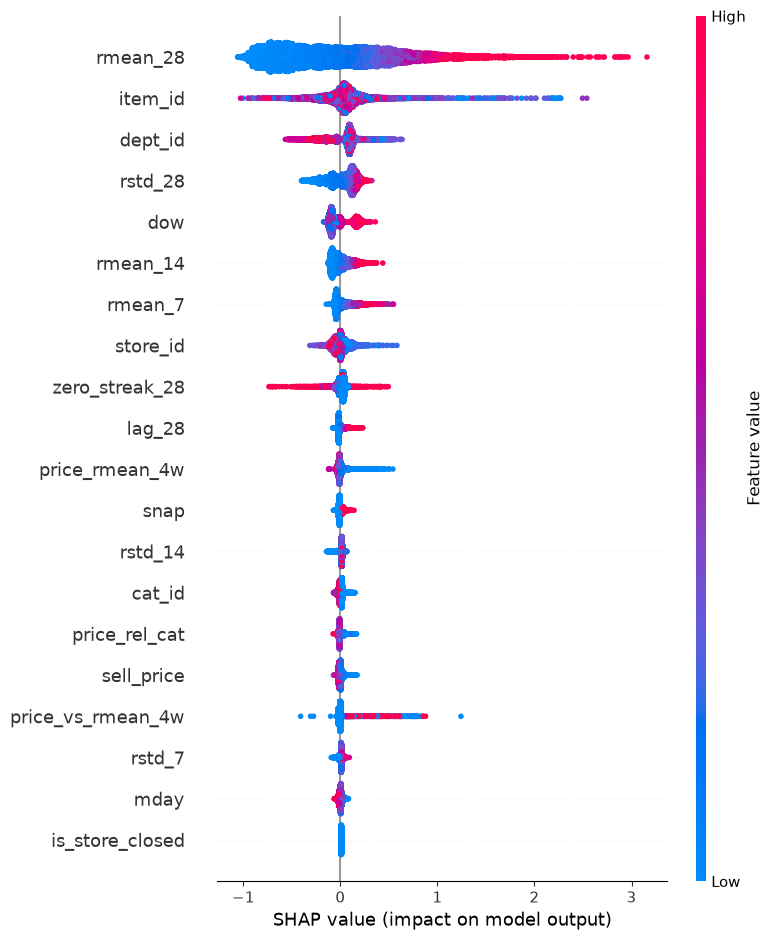

rmean_28         0.5084
item_id          0.1503
dept_id          0.1300
rstd_28          0.1198
dow              0.0998
rmean_14         0.0718
rmean_7          0.0642
store_id         0.0541
zero_streak_28   0.0327
lag_28           0.0236
price_rmean_4w   0.0219
snap             0.0196
rstd_14          0.0195
cat_id           0.0180
price_rel_cat    0.0167
dtype: float64

In [10]:
val_dates = ctx["actual"].columns
shap_values, X_sample = analysis.shap_sample(FINAL, val_dates[0], val_dates[-1], n=20_000)
shap.summary_plot(shap_values.to_numpy(), X_sample, max_display=20, show=False)
plt.tight_layout()
plt.show()
shap_values.abs().mean().sort_values(ascending=False).head(15)

## Findings

1. **Error is spread out, not concentrated.** The top 20 series carry 4.2% of level-12 error (2.7% of weight);
   error shares track dollar weights closely for every category and department (over-index 0.90-1.06).
2. **WI_2 is the hardest store** (over-index 1.16, weighted RMSSE 0.98 vs 0.76-0.88 elsewhere) - it is also the
   hardest store for Seasonal Naive (1.29), so it is a noisier store rather than a model-specific failure. FOODS_2 is the
   hardest department (over-index 1.06).
3. **The largest single errors come from unexplained level changes**, not from intermittency, prices or events:
   spikes/drops in the last 28 train days that the >= 28-day-lagged features still carry into val (over-forecast), and
   surges starting inside val with no price or event signal (under-forecast).
4. **Systematic under-forecast, worst on weekends.** Total 28-day bias is -2.4%; at the total level the signed scaled
   error is negative on Sunday (-0.48) and Saturday (-0.28), and Sunday has the highest error at both levels.
5. **No degradation with horizon.** Every horizon day uses the same >= 28-day-old information, so error varies with the
   weekday, not with h.
6. **Intermittent series are slightly harder but small in weight.** The 80-100% zero bucket over-indexes by 4% but holds
   6.5% of weight; series with < 50% zeros hold 66% of weight and 65% of error. LightGBM beats Seasonal Naive by
   0.26-0.36 in every bucket.
7. **SHAP agrees with gain on `rmean_28`** (mean |SHAP| 0.51) but ranks `dow` (0.10) and `dept_id` far higher than
   gain does, so day-of-week matters for individual predictions even though it adds little split gain.

Ideas this suggests for the next round (to be selected on the inner window, not here): horizon-specific models
(e.g. days 1-7 with lag 7-27 features, to see recent level changes), a weekend/Sunday correction, and per-store models
for stores like WI_2.